# Rate-Distortion, Compression, and the Information Bottleneck

**AI Mathematics · 6. Information Theory**

Relate information to lossy compression, representation learning, and the trade-off between compactness and predictive usefulness.

> The emphasis is on short, reusable examples rather than long projects. Code examples use Python and NumPy unless noted otherwise.

## Learning objectives
- Define rate and distortion conceptually.
- Compare simple distortion functions.
- Understand the information bottleneck objective at a high level.

In [1]:
import numpy as np

## 1. Rate-distortion intuition
Rate-distortion theory studies the minimum information rate needed to represent data while keeping expected distortion below a chosen level. Rate is related to the number of bits used; distortion is a task-dependent measure of reconstruction error. There is no universally best distortion measure.

In [2]:
import numpy as np

original = np.array([0.0, 0.2, 0.4, 0.6, 0.8, 1.0])
reconstruction = np.array([0.0, 0.0, 0.5, 0.5, 1.0, 1.0])
print("MSE distortion:", np.mean((original-reconstruction)**2))
print("MAE distortion:", np.mean(np.abs(original-reconstruction)))

MSE distortion: 0.016666666666666663
MAE distortion: 0.09999999999999998


## 2. Quantization and rate
A simple compressor maps a continuous range of values to a finite set of levels. Fewer levels usually reduce storage rate while increasing reconstruction error. Actual compression rate also depends on how frequently each level occurs and how efficiently symbols are encoded.

In [3]:
def quantize(x, levels):
    x = np.asarray(x, dtype=float)
    if levels < 2:
        raise ValueError("levels must be at least 2")
    return np.round(x*(levels-1))/(levels-1)

x = np.linspace(0, 1, 11)
for levels in [2, 4, 8]:
    q = quantize(x, levels)
    bits_per_value = np.log2(levels)
    print("levels:", levels, "nominal bits/value:", bits_per_value, "MSE:", np.mean((x-q)**2))

levels: 2 nominal bits/value: 1.0 MSE: 0.07727272727272726
levels: 4 nominal bits/value: 2.0 MSE: 0.008585858585858584
levels: 8 nominal bits/value: 3.0 MSE: 0.001576994434137291


## 3. Distortion depends on the task
Pixel-level MSE penalizes squared numerical differences. Perceptual distortion may judge two images as similar even when pixels differ, while a downstream task may care about preserving edges, objects, or semantics. In ML, the evaluation metric should match the intended use.

In [4]:
# A tiny example comparing absolute and squared error
errors = np.array([0.1, 0.1, 1.0])
print("MAE:", np.mean(np.abs(errors)))
print("MSE:", np.mean(errors**2))
print("MSE emphasizes the large error more strongly than MAE.")

MAE: 0.39999999999999997
MSE: 0.34
MSE emphasizes the large error more strongly than MAE.


## 4. Information bottleneck
The information bottleneck idea seeks a representation \(Z\) that compresses input \(X\) while retaining information about target \(Y\). A conceptual objective is to reduce \(I(X;Z)\) while preserving \(I(Z;Y)\). Exact mutual information is often difficult to estimate, so practical methods use variational bounds and task-specific proxies.

In [5]:
# Conceptual trade-off table; values are illustrative, not empirical.
representations = [
    {"name": "high-capacity", "input_information": 9.0, "target_information": 8.5},
    {"name": "compressed", "input_information": 3.0, "target_information": 7.8},
    {"name": "over-compressed", "input_information": 1.0, "target_information": 2.0},
]
for item in representations:
    print(item)

{'name': 'high-capacity', 'input_information': 9.0, 'target_information': 8.5}
{'name': 'compressed', 'input_information': 3.0, 'target_information': 7.8}
{'name': 'over-compressed', 'input_information': 1.0, 'target_information': 2.0}


## 5. Applications and limitations
Rate-distortion concepts appear in image/audio compression, learned codecs, representation learning, and communication systems. They provide a framework for trade-offs, not a single formula that automatically chooses a good representation. The answer depends on distortion, data distribution, and constraints.

### Choosing the right Python tool

- **NumPy** handles arrays, vectorized arithmetic, linear algebra, random sampling, and numerical operations.
- **pandas** is useful for named columns, tabular summaries, and experiment logs.
- **Matplotlib** gives low-level control over vector arrows, geometry, contour plots, and custom figures.
- **Seaborn** is built on Matplotlib and makes statistical plots such as heatmaps, distributions, and grouped comparisons quick to create.

Not every mathematical idea needs all four libraries. The extra examples use each tool where it clarifies the concept. Plots are diagnostic aids: always inspect axes, units, assumptions, and sample size.

## Practical lab: visualize a rate–distortion trade-off

Rate–distortion theory asks how much information is needed to represent a source at a specified level of distortion. This toy scalar quantizer rounds values to a finite number of levels. More levels usually reduce reconstruction error but require more bits per symbol. Real compression methods exploit structure and dependencies in the data.

19_rate_distortion_and_information_bottleneck.ipynb:cell14:24: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
19_rate_distortion_and_information_bottleneck.ipynb:cell14:28: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


,bits per sample,levels,MSE distortion
0,1,2,0.10697
1,2,4,0.03209
2,3,8,0.00885
3,4,16,0.00219
4,5,32,0.00057
5,6,64,0.00014


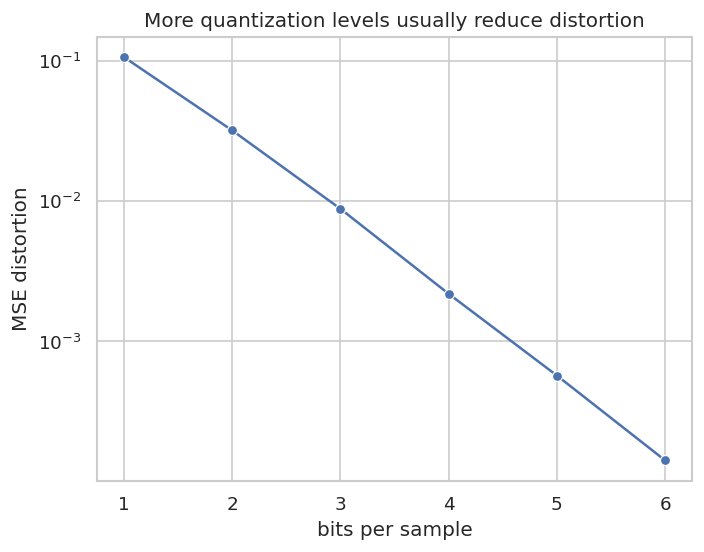

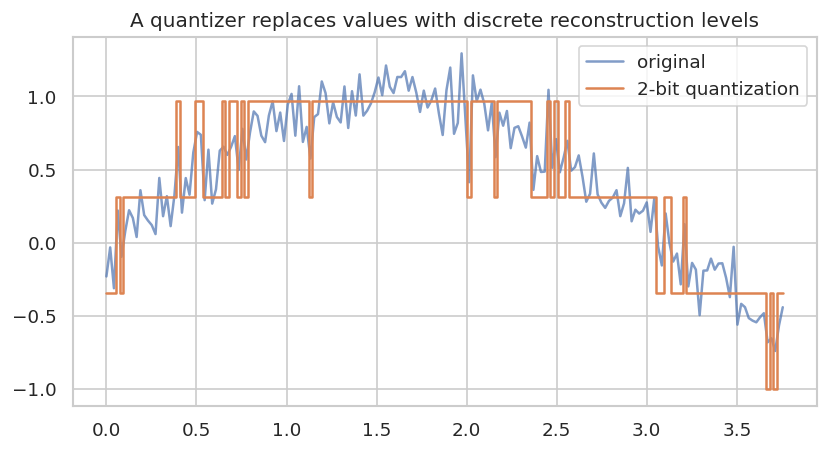

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
sns.set_theme(style="whitegrid")
viz_rd_rng = np.random.default_rng(84)
viz_rd_t = np.linspace(0, 4*np.pi, 600)
viz_rd_signal = np.sin(viz_rd_t) + 0.15*viz_rd_rng.normal(size=viz_rd_t.size)
viz_rd_rows = []
viz_rd_reconstructions = {}
for viz_rd_bits in range(1, 7):
    levels = 2**viz_rd_bits
    lo, hi = viz_rd_signal.min(), viz_rd_signal.max()
    bin_width = (hi-lo)/levels
    viz_rd_recon = lo + (np.floor((viz_rd_signal-lo)/bin_width)+0.5)*bin_width
    viz_rd_recon = np.clip(viz_rd_recon, lo+bin_width/2, hi-bin_width/2)
    viz_rd_mse = np.mean((viz_rd_signal-viz_rd_recon)**2)
    viz_rd_rows.append({"bits per sample": viz_rd_bits, "levels": levels, "MSE distortion": viz_rd_mse})
    viz_rd_reconstructions[viz_rd_bits] = viz_rd_recon
viz_rd_df = pd.DataFrame(viz_rd_rows)
display(viz_rd_df.round(5))
sns.lineplot(data=viz_rd_df, x="bits per sample", y="MSE distortion", marker="o")
plt.yscale("log"); plt.title("More quantization levels usually reduce distortion"); plt.show()
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(viz_rd_t[:180], viz_rd_signal[:180], label="original", alpha=0.7)
ax.step(viz_rd_t[:180], viz_rd_reconstructions[2][:180], where="mid", label="2-bit quantization")
ax.legend(); ax.set_title("A quantizer replaces values with discrete reconstruction levels"); plt.show()

### Interpret the curve

The curve is not expected to be linear. The exact rate–distortion function depends on the source distribution, distortion measure, and coding assumptions. Here the bit count is a simple proxy for rate and mean squared error (MSE) is the distortion measure.

## Practice exercises
Try each exercise before looking at the suggested solution. These are intentionally small so you can change values and observe how the result changes.

### Exercise 1
Exercise 1: Quantize [0.1, 0.5, 0.9] to 3 levels.

In [7]:
print(quantize([0.1, 0.5, 0.9], levels=3))

[0.  0.5 1. ]


### Exercise 2
Exercise 2: Explain why MSE and perceptual similarity may disagree.

In [8]:
# MSE compares numerical coordinate errors, while perceptual similarity depends on structure and task-relevant features.

## Key takeaways
- Rate-distortion formalizes the trade-off between compression rate and reconstruction quality.
- The distortion measure encodes which errors matter for an application.
- Information bottleneck ideas seek compact representations that retain information useful for prediction.

**Next step:** Change an input, check the shapes or assumptions, and rerun the relevant cell. That habit is central to mathematical programming.